# 06 — Resultados finales

**Objetivo.** Reunir las tablas y figuras del capítulo 5: la tabla maestra de todos los modelos,
el ensemble de semillas, la comparación con la clasificación oficial del BGLP 2020, la
anticipación de la alarma, el rendimiento de noche frente a día y episodios de ejemplo.

**Protocolo.** Test oficial (primera hora descartada en la cohorte 2020), tolerancia de 15 min,
61 eventos puntuables, alarma `P(y<70) > α` con α elegido en validación y presupuesto de 1 falsa
alarma/día salvo que se diga otra cosa. Todo recall lleva su IC95 % bootstrap sobre eventos.

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tfm.data.loaders import load_cgm
from tfm.data.parser import PATIENTS_2020
from tfm.eval.alarm import predictions_from_experiment
from tfm.eval.analysis import (alarm_tables, bglp_metrics, coverage, lead_time_summary,
                               master_row, period_breakdown, pick_examples)
from tfm.eval.compare import _paired, holm, load_result
from tfm.eval.protocol import scorable_events_by_patient
from tfm.paths import RESULTS_DIR
from tfm.viz.plots import (plot_examples, plot_lead_times, plot_period_breakdown,
                           save_figure, set_style)

set_style()
pd.set_option("display.width", 160)
ENSEMBLE = "20260930-global-bigru-ensemble"
MODELS = {"Persistencia": "20260915-baseline-persistencia", "Ridge": "20260916-baseline-ridge",
          "LSTM por paciente": "20260916-baseline-lstm-paciente",
          "LSTM global": "20260916-baseline-lstm-global",
          "Transformer global": "20260916-global-transformer",
          "BiGRU global": "20260916-global-bigru", "Ensemble BiGRU": ENSEMBLE}
ens, alpha_val = load_result(ENSEMBLE), load_result("20260928-global-bigru-alpha-val")

## 1. Tabla maestra

Una fila por modelo y horizonte. RMSE, Clarke A+B y Parkes D+E agregados sobre todas las
predicciones (media entre semillas cuando hay varias); MAE y gRMSE, media entre pacientes.
`recall_mu70` es la regla `μ < 70`; las columnas de alarma solo existen para los modelos con α
elegido en validación (BiGRU, media entre semillas, y ensemble). El Transformer no tiene α en
validación: su alarma de la Fase 4 se eligió sobre el test y no se reporta.

In [2]:
filas = []
for h in (30, 60):
    for nombre, exp in MODELS.items():
        alarma = None
        if exp == "20260916-global-bigru":
            a = alpha_val["aggregate"][str(h)]["1.0"]
            alarma = {"recall": a["recall"],
                      "false_alarms_per_day": float(np.mean(a["false_alarms_per_day_by_seed"]))}
        elif exp == ENSEMBLE:
            a = ens["alarm"][str(h)]["1.0"]
            alarma = {"recall": a["recall"], "false_alarms_per_day": a["false_alarms_per_day"],
                      "median_lead_time_min": a["lead_time"]["median"]}
        filas.append(master_row(nombre, load_result(exp), h, alarma))
maestra = pd.DataFrame(filas)
maestra.round(3)

,modelo,PH,rmse,mae_media_pacientes,grmse_media_pacientes,clarke_AB,parkes_DE,recall_mu70,recall_alarma,ic_lo,ic_hi,n_eventos,fa_dia_alarma,anticipacion_mediana_min
0,Persistencia,30,23.498,16.954,26.260,98.993,0.000,0.098,NaN,NaN,NaN,NaN,NaN,NaN
1,Ridge,30,19.412,13.589,22.195,98.940,0.003,0.279,NaN,NaN,NaN,NaN,NaN,NaN
2,LSTM por paciente,30,21.880,15.640,25.501,98.138,0.000,0.077,NaN,NaN,NaN,NaN,NaN,NaN
3,LSTM global,30,19.024,13.408,21.989,98.543,0.000,0.038,NaN,NaN,NaN,NaN,NaN,NaN
4,Transformer global,30,19.535,13.708,22.596,98.703,0.000,0.137,NaN,NaN,NaN,NaN,NaN,NaN
5,BiGRU global,30,18.973,13.324,21.753,98.855,0.000,0.186,0.574,0.475,0.672,61.0,0.780,NaN
6,Ensemble BiGRU,30,18.840,13.196,21.612,98.863,0.000,0.115,0.836,0.738,0.918,61.0,0.964,25.0
7,Persistencia,60,38.550,28.476,44.074,96.802,0.170,0.066,NaN,NaN,NaN,NaN,NaN,NaN
8,Ridge,60,32.557,23.829,38.903,96.519,0.073,0.066,NaN,NaN,NaN,NaN,NaN,NaN
9,LSTM por paciente,60,33.438,24.435,40.229,96.438,0.027,0.038,NaN,NaN,NaN,NaN,NaN,NaN


El ensemble tiene el menor error de todos los modelos (RMSE 18,84 / 31,29 mg/dL). Con una falsa
alarma al día y α elegido en validación, su alarma detecta 0,836 (IC95 % 0,738–0,918) de los 61
eventos a 30 min, frente a 0,574 de la media de las semillas; la sección 2 muestra que esa
diferencia se debe sobre todo a dónde cae α, no al ensemble. La regla `μ < 70` sigue siendo pobre en
todos los modelos (0,04–0,28). A 60 min ninguna alarma pasa de 0,07 con ese presupuesto.

## 2. Ensemble frente a cada semilla

α, recall con IC y falsas alarmas/día en test, para cada presupuesto, del ensemble y de cada
semilla (las cifras de las semillas coinciden con `20260928-global-bigru-alpha-val`).

In [3]:
filas = []
for h in ("30", "60"):
    for b in ("0.5", "1.0", "2.0"):
        a = ens["alarm"][h][b]
        filas.append({"PH": int(h), "FA/día máx.": float(b), "modelo": "ensemble",
                      "α": a["alpha"], "recall": a["recall"]["point"],
                      "IC95 %": f"[{a['recall']['lo']:.3f}–{a['recall']['hi']:.3f}]",
                      "FA/día test": a["false_alarms_per_day"], "recall val": a["val_recall"]})
        for s, m in ens["members"].items():
            r = m[h]["alarm"][b]
            filas.append({"PH": int(h), "FA/día máx.": float(b), "modelo": f"semilla {s}",
                          "α": r["alpha"], "recall": r["recall"]["point"],
                          "IC95 %": f"[{r['recall']['lo']:.3f}–{r['recall']['hi']:.3f}]",
                          "FA/día test": alpha_val["aggregate"][h][b]["false_alarms_per_day_by_seed"][int(s)],
                          "recall val": alpha_val["by_seed"][s][h][b]["val_recall"]})
pd.DataFrame(filas).round(3)

,PH,FA/día máx.,modelo,α,recall,IC95 %,FA/día test,recall val
0,30,0.5,ensemble,0.50,0.115,[0.049–0.197],0.308,0.217
1,30,0.5,semilla 0,0.50,0.115,[0.049–0.197],0.211,0.203
2,30,0.5,semilla 1,0.50,0.230,[0.131–0.344],0.486,0.275
3,30,0.5,semilla 2,0.50,0.213,[0.115–0.311],0.372,0.261
4,30,1.0,ensemble,0.30,0.836,[0.738–0.918],0.964,0.739
5,30,1.0,semilla 0,0.30,0.787,[0.672–0.885],0.956,0.797
6,30,1.0,semilla 1,0.40,0.459,[0.328–0.574],0.737,0.449
7,30,1.0,semilla 2,0.40,0.475,[0.344–0.591],0.648,0.565
8,30,2.0,ensemble,0.20,0.951,[0.885–1.000],1.644,0.913
9,30,2.0,semilla 0,0.20,0.967,[0.918–1.000],1.555,0.884


Wilcoxon pareado por paciente (12 pacientes): ensemble frente a la media de las tres semillas,
en RMSE y en recall de la alarma con 1 falsa alarma/día. Holm dentro de cada métrica (2 tests).

In [4]:
def por_paciente(block_pp, alarm_pp):
    t = pd.DataFrame(block_pp)[["patient", "rmse"]]
    a = pd.DataFrame(alarm_pp)
    a["recall"] = a["n_detected"] / a["n_events"]
    return t.merge(a[["patient", "recall"]], on="patient", how="left")

pruebas = []
for h in ("30", "60"):
    e = por_paciente(ens["by_horizon"][h]["per_patient"], ens["alarm"][h]["1.0"]["per_patient"])
    semillas = (pd.concat([por_paciente(m[h]["per_patient"], m[h]["alarm"]["1.0"]["per_patient"])
                           for m in ens["members"].values()])
                .groupby("patient").mean().reset_index())
    both = e.merge(semillas, on="patient", suffixes=("_ens", "_semillas"))
    for metrica in ("rmse", "recall"):
        pruebas.append({"PH": int(h), "métrica": metrica,
                        **_paired(both[f"{metrica}_ens"].to_numpy(),
                                  both[f"{metrica}_semillas"].to_numpy())})
pruebas = pd.DataFrame(pruebas)
pruebas["p_holm"] = pruebas.groupby("métrica")["p_value"].transform(lambda p: holm(p.to_numpy()))
pruebas.round(4)

,PH,métrica,n,median_a,median_b,median_diff,statistic,p_value,p_holm
0,30,rmse,12,18.2880,18.4205,-0.1308,0.0,0.0005,0.0010
1,30,recall,12,0.8661,0.6458,0.2917,1.0,0.0078,0.0156
2,60,rmse,12,30.4432,30.6608,-0.1669,0.0,0.0005,0.0010
3,60,recall,12,0.0000,0.0000,0.0000,2.0,0.3750,0.3750


Paciente a paciente, el ensemble mejora a la media de las semillas en RMSE en los dos horizontes
(mediana −0,13 y −0,17 mg/dL, p_Holm 0,001). En recall a 30 min la mejora (mediana +0,29, p_Holm
0,016) compara cada modelo **con su propio α elegido en validación**: el ensemble trabaja con α = 0,3
y 0,96 falsas alarmas/día en test, y las semillas 1 y 2 con α = 0,4 y 0,74 y 0,65 falsas alarmas/día.
A 60 min el recall no cambia (p = 0,38).

**A igual α.** El α elegido en validación no es el mismo para todos (0,3 para el ensemble y la
semilla 0; 0,4 para las semillas 1 y 2), y en esta rejilla un paso de α cambia mucho el recall.
Para separar el efecto del ensemble del efecto del punto de operación, esta tabla describe el test
con los mismos α para todos. Es descriptiva: no elige nada.

In [5]:
eventos_test = scorable_events_by_patient(predictions_from_experiment(ENSEMBLE))
fuentes = {"ensemble": predictions_from_experiment(ENSEMBLE),
           **{f"semilla {s}": predictions_from_experiment("20260916-global-bigru", s) for s in (0, 1, 2)}}
filas = []
for nombre, by in fuentes.items():
    for h in (30, 60):
        for a in (0.2, 0.25, 0.3, 0.4):
            t = alarm_tables(by[h], eventos_test, a)
            filas.append({"PH": h, "α": a, "modelo": nombre,
                          "detectados": int(t.events["detected"].sum()),
                          "recall": float(t.events["detected"].mean()),
                          "FA/día": len(t.false_alarms) / t.span_days})
igual_alpha = pd.DataFrame(filas).pivot_table(index=["PH", "α"], columns="modelo",
                                              values=["detectados", "FA/día"])
igual_alpha.round(3)

FA/día                               detectados                              
modelo  ensemble semilla 0 semilla 1 semilla 2   ensemble semilla 0 semilla 1 semilla 2
PH α                                                                                   
30 0.20    1.644     1.555     1.660     1.563       58.0      59.0      58.0      59.0
   0.25    1.166     1.255     1.368     1.215       57.0      58.0      56.0      57.0
   0.30    0.964     0.956     1.020     0.996       51.0      48.0      50.0      52.0
   0.40    0.615     0.567     0.737     0.648       29.0      18.0      28.0      29.0
60 0.20    2.097     2.211     2.089     1.976       34.0      39.0      32.0      29.0
   0.25    1.344     1.482     1.385     1.344       22.0      24.0      20.0      20.0
   0.30    0.891     0.980     0.988     0.875       17.0      19.0      16.0      16.0
   0.40    0.421     0.413     0.470     0.445        4.0       5.0       3.0       5.0

Con el mismo α, el ensemble y las semillas detectan prácticamente lo mismo: con α = 0,3, 51, 48, 50
y 52 de los 61 eventos a 30 min con 0,96–1,02 falsas alarmas/día; con α = 0,4, 29, 18, 28 y 29. La
ganancia del ensemble de la tabla anterior viene, por tanto, del punto de operación: en validación
las semillas 1 y 2 pasaban de una falsa alarma al día con α = 0,3 y el presupuesto las llevó a 0,4,
y en esta rejilla ese paso reduce el recall casi a la mitad. Lo que sí aporta el ensemble es un
modelo único, sin semilla que elegir, algo menos de error y un α que en validación cayó en 0,3. La
lección metodológica es que la rejilla de α es demasiado gruesa entre 0,3 y 0,4.

### Curva de operación del ensemble

Recall frente a falsas alarmas/día al barrer α sobre el test. La curva es **descriptiva**: el único
punto que se reporta como resultado es el α elegido en validación con el presupuesto de una falsa
alarma al día (estrella).

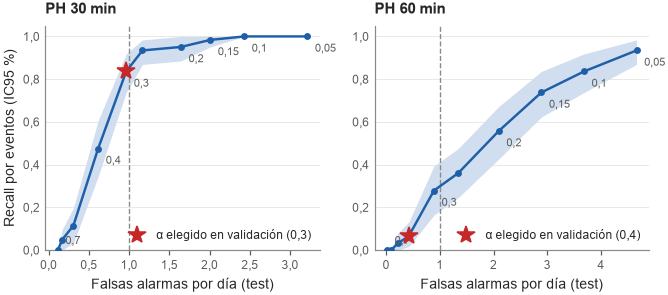

alpha  recall  recall_lo  recall_hi  false_alarms_per_day
PH                                                             
30 0   0.05   1.000      1.000      1.000                 3.215
   1   0.10   1.000      1.000      1.000                 2.429
   2   0.15   0.984      0.951      1.000                 2.008
   3   0.20   0.951      0.885      1.000                 1.644
   4   0.25   0.934      0.869      0.984                 1.166
   5   0.30   0.836      0.738      0.918                 0.964
   6   0.40   0.475      0.344      0.607                 0.615
   7   0.50   0.115      0.033      0.197                 0.308
   8   0.60   0.049      0.000      0.098                 0.170
   9   0.70   0.000      0.000      0.000                 0.113
60 0   0.05   0.934      0.869      0.984                 4.664
   1   0.10   0.836      0.738      0.918                 3.684
   2   0.15   0.738      0.623      0.836                 2.891
   3   0.20   0.557      0.426      0.672                 2.097
   4   0.25   0.361      0.246      0.475                 1.344
   5   0.30   0.279      0.164      0.393                 0.891
   6   0.40   0.066      0.016      0.131                 0.421
   7   0.50   0.033      0.000      0.082                 0.227
   8   0.60   0.000      0.000      0.000                 0.089
   9   0.70   0.000      0.000      0.000                 0.016

In [6]:
from tfm.eval.alarm import operating_curve
from tfm.viz.plots import plot_operating_curve

by_h_ens = predictions_from_experiment(ENSEMBLE)
eventos_ens = scorable_events_by_patient(by_h_ens)
curvas = {h: operating_curve(by_h_ens[h], eventos_ens) for h in by_h_ens}
fig = plot_operating_curve(curvas, {h: ens["alarm"][str(h)]["1.0"]["alpha"] for h in curvas})
save_figure(fig, "06_curva_operacion")
plt.show()
pd.concat(curvas, names=["PH"])[["alpha", "recall", "recall_lo", "recall_hi",
                                "false_alarms_per_day"]].round(3)

A 30 min la curva sube en vertical hasta α = 0,3: con 0,96 falsas alarmas/día se detectan 0,836
de los eventos, y aceptar 1,17 al día (α = 0,25) lleva a 0,934. A 60 min la curva es mucho más
tendida: con α = 0,3 el test habría dado 0,279 con 0,89 falsas alarmas/día, pero en validación ese
α no cabía en el presupuesto y se eligió 0,4 (0,066). El punto de operación se decide en una zona
en la que un paso de α cambia mucho el recall.

## 3. Comparación con el BGLP 2020

Clasificación oficial de los 8 sistemas conformes a las reglas (prefacio del Vol-2675 de CEUR-WS,
Tabla 1; reproducida en el capítulo 3 de la memoria). Métricas sobre los 6 pacientes de
2020, media de las métricas por paciente, ordenadas por la suma de las cuatro. Nuestros modelos se
puntúan igual; con varias semillas, la media entre ellas. **Advertencia**: los participantes
predecían todos los puntos oficiales y nosotros no generamos ventanas que crucen huecos de más de
30 min; la cobertura se muestra al lado y la comparación es orientativa.

In [7]:
oficial = pd.DataFrame(
    [("Rubin-Falcone et al.", 18.22, 12.83, 31.66, 23.60), ("Hameed y Kleinberg", 19.21, 13.08, 31.77, 23.09),
     ("Zhu et al.", 18.34, 13.37, 32.21, 24.20), ("Yang et al.", 19.05, 13.50, 32.03, 23.83),
     ("Bevan y Coenen", 18.23, 14.37, 31.10, 25.75), ("Sun et al.", 19.37, 13.76, 32.59, 24.64),
     ("Joedicke et al.", 19.60, 14.25, 34.12, 25.99), ("Ma et al.", 20.03, 14.52, 34.89, 26.41)],
    columns=["sistema", "rmse_30", "mae_30", "rmse_60", "mae_60"])
oficial["sum"] = oficial[["rmse_30", "mae_30", "rmse_60", "mae_60"]].sum(axis=1)
oficial["cobertura_30"] = oficial["cobertura_60"] = 1.0

puntos = {p: load_cgm(p, "test")["ts"].to_numpy() for p in PATIENTS_2020}
nuestros = []
for nombre in ("Persistencia", "Ridge", "LSTM global", "BiGRU global", "Ensemble BiGRU"):
    frame = pd.read_parquet(RESULTS_DIR / MODELS[nombre] / "predictions.parquet")
    m = bglp_metrics(frame)
    nuestros.append({"sistema": f"{nombre} (este TFM)", **{k: m[k] for k in
                     ("rmse_30", "mae_30", "rmse_60", "mae_60", "sum")},
                     "cobertura_30": coverage(frame, puntos, 30),
                     "cobertura_60": coverage(frame, puntos, 60)})
bglp = pd.concat([oficial, pd.DataFrame(nuestros)], ignore_index=True).sort_values("sum")
bglp.round(3)

,sistema,rmse_30,mae_30,rmse_60,mae_60,sum,cobertura_30,cobertura_60
0,Rubin-Falcone et al.,18.220,12.830,31.660,23.600,86.310,1.000,1.000
1,Hameed y Kleinberg,19.210,13.080,31.770,23.090,87.150,1.000,1.000
12,Ensemble BiGRU (este TFM),18.646,13.340,31.921,23.768,87.674,0.934,0.934
2,Zhu et al.,18.340,13.370,32.210,24.200,88.120,1.000,1.000
11,BiGRU global (este TFM),18.780,13.473,32.092,23.878,88.222,0.934,0.934
3,Yang et al.,19.050,13.500,32.030,23.830,88.410,1.000,1.000
10,LSTM global (este TFM),18.882,13.611,32.102,23.945,88.541,0.934,0.934
9,Ridge (este TFM),18.660,13.579,32.491,24.315,89.045,0.934,0.934
4,Bevan y Coenen,18.230,14.370,31.100,25.750,89.450,1.000,1.000
5,Sun et al.,19.370,13.760,32.590,24.640,90.360,1.000,1.000


Con la agregación oficial, el ensemble sumaría 87,67 y quedaría tercero, entre Hameed y Kleinberg
(87,15) y Zhu et al. (88,12); el BiGRU (media de las tres semillas por separado), con 88,22,
quedaría cuarto, e incluso el ridge (89,05) quedaría por delante de cuatro sistemas publicados. **Pero la comparación es orientativa**: se
puntúa el 93,4 % de los puntos oficiales, porque no se predicen los instantes tras huecos de más de
30 min, que suelen ser más difíciles, y cada sistema tomó sus propias decisiones de
preprocesado.

## 4. Modelo de referencia y anticipación de la alarma

Regla de la spec: los análisis 4–6 usan el ensemble salvo que su recall en **validación** (30 min,
1 falsa alarma/día) sea menor que el de la semilla mediana. La comprobación no mira el test.

In [8]:
val_semillas = sorted(alpha_val["by_seed"][s]["30"]["1.0"]["val_recall"] for s in alpha_val["by_seed"])
val_ens = ens["alarm"]["30"]["1.0"]["val_recall"]
print(f"validación: ensemble {val_ens:.3f}, semilla mediana {val_semillas[1]:.3f}")
assert val_ens >= val_semillas[1], "usar la semilla mediana en las secciones 4-6"

by_h = predictions_from_experiment(ENSEMBLE)
eventos = scorable_events_by_patient(by_h)
tablas = {h: alarm_tables(by_h[h], eventos, ens["alarm"][str(h)]["1.0"]["alpha"]) for h in by_h}
display(pd.DataFrame({h: lead_time_summary(t.events) for h, t in tablas.items()}).T)
# eventos detectados con cada anticipación (min)
pd.DataFrame({h: t.events.loc[t.events["detected"].astype(bool), "lead_time_min"].value_counts()
              for h, t in tablas.items()}).sort_index().fillna(0).astype(int)

validación: ensemble 0.739, semilla mediana 0.565


,n_detected,median,q1,q3,min,max,n_negative
30,51.0,25.0,20.00,45.0,15.0,45.0,0.0
60,4.0,62.5,48.75,75.0,45.0,75.0,0.0


,30,60
lead_time_min,,
15.0,9,0
20.0,14,0
25.0,7,0
30.0,2,0
35.0,1,0
40.0,4,0
45.0,14,1
50.0,0,1
75.0,0,2


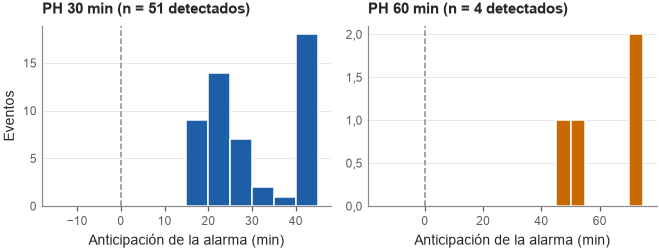

In [9]:
fig = plot_lead_times(tablas)
save_figure(fig, "06_anticipacion")
plt.show()

A 30 min la anticipación de los 51 eventos detectados va de 15 a 45 min (mediana 25, rango
intercuartílico 20–45). Esos límites no son un resultado: con una tolerancia de 15 min, una alarma
cuenta si su instante predicho cae a ±15 min del inicio, y la alarma suena 30 min antes de ese
instante, así que la anticipación está acotada entre 15 y 45 min y nunca puede ser negativa. Lo
informativo es la forma: 14 de los 51 eventos se detectan en el límite de 45 min, es decir, la
alarma ya saltaba antes de la ventana de tolerancia. A 60 min solo hay 4 detecciones, así que su
mediana de 62,5 min no se interpreta.

## 5. Noche frente a día

Noche = inicio del evento (o de la falsa alarma, en el instante en que suena) entre las 00:00 y
las 06:00. Las falsas alarmas/día de cada franja se dividen por los días de todo el test, así que
suman la tasa total. El RMSE usa las ventanas cuya hora objetivo cae en la franja.

n_events  n_detected  recall  recall_lo  recall_hi  false_alarms_per_day    rmse
PH franja                                                                                  
30 noche         18          17   0.944      0.833      1.000                 0.267  13.141
   día           43          34   0.791      0.651      0.907                 0.696  20.488
60 noche         18           2   0.111      0.000      0.278                 0.154  21.625
   día           43           2   0.047      0.000      0.116                 0.267  34.059

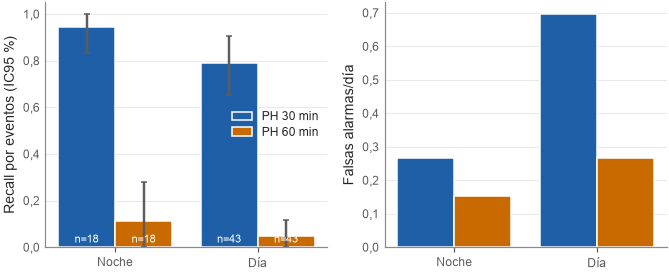

In [10]:
franjas = {h: period_breakdown(tablas[h], by_h[h]) for h in tablas}
display(pd.concat(franjas, names=["PH", "franja"]).round(3))
fig = plot_period_breakdown(franjas)
save_figure(fig, "06_noche_dia")
plt.show()

De noche el ensemble detecta 17 de 18 eventos a 30 min (0,944, IC95 % 0,833–1,000) frente a 34 de
43 de día (0,791, IC 0,651–0,907), con menos falsas alarmas (0,27 frente a 0,70 al día) y menos
error (RMSE 13,1 frente a 20,5 mg/dL). Es coherente con que la noche no tenga comidas ni bolos que
perturben la serie. Los IC se solapan, así que la diferencia de recall no es concluyente; la de
RMSE es grande. Es relevante clínicamente porque la hipoglucemia nocturna es la que el paciente
no percibe.

## 6. Episodios de ejemplo

Elegidos por una regla fija sobre el ensemble a 30 min con 1 falsa alarma/día: el evento detectado
con la anticipación mediana, el de anticipación máxima, el no detectado con el nadir más bajo y la
falsa alarma más larga. El eje horizontal es el instante al que se refiere la predicción.

,detected,end,lead_time_min,minutes,nadir,patient,start
median_lead,True,NaN,25.0,NaN,43.0,591,2022-01-14 04:40:00
max_lead,True,NaN,45.0,NaN,62.0,563,2021-11-04 19:15:00
worst_miss,False,NaN,NaN,NaN,40.0,575,2022-01-09 22:00:00
longest_false_alarm,NaN,2025-05-28 02:55:00,NaN,70.0,NaN,552,2025-05-28 01:50:00


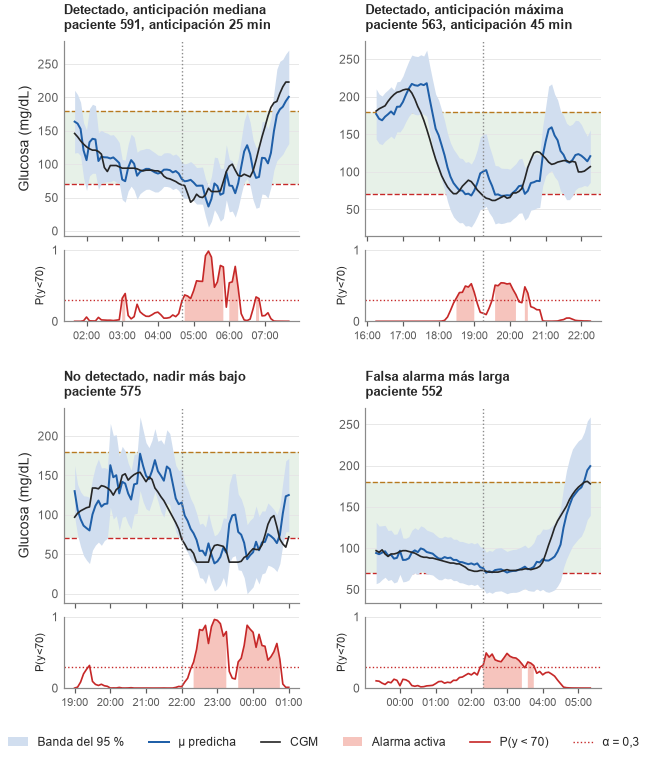

In [11]:
picks = pick_examples(tablas[30])
display(pd.DataFrame({k: v for k, v in picks.items() if v is not None}).T)
frame = pd.read_parquet(RESULTS_DIR / ENSEMBLE / "predictions.parquet")
fig = plot_examples(frame, picks, ens["alarm"]["30"]["1.0"]["alpha"], 30)
save_figure(fig, "06_episodios")
plt.show()

Arriba, dos detecciones: en 591 la probabilidad supera α para un instante 5 min posterior al
inicio, lo que da 25 min de aviso; en 563 la probabilidad ya supera α durante la bajada, antes de
la ventana de tolerancia, y el aviso computado es el máximo posible, 45 min.
Abajo a la izquierda, el fallo más grave (575, nadir de 40 mg/dL, el suelo del sensor): la
probabilidad cruza α para instantes más de 15 min posteriores al inicio, fuera de la tolerancia;
el modelo va por detrás de una caída rápida. Abajo a la derecha, la falsa alarma más larga (552, 70 min) es en
realidad un casi-evento: la CGM se queda en 71–75 mg/dL durante más de una hora, justo por encima
del umbral. Clínicamente ese aviso no sería inútil.

## 7. Por paciente

Métricas del ensemble por paciente, con el número de eventos de test junto a cada recall: en los
pacientes con uno o dos eventos el recall individual no se interpreta. El recall de esta tabla es
el de la regla `μ < 70`; el de la alarma por paciente va en la segunda tabla.

In [12]:
pp = pd.concat({h: pd.DataFrame(ens["by_horizon"][h]["per_patient"]).set_index("patient")
                [["n_events", "rmse", "mae", "clarke_AB", "parkes_DE"]] for h in ("30", "60")}, axis=1)
pp.round(2)

30                                         60                                  
        n_events   rmse    mae clarke_AB parkes_DE n_events   rmse    mae clarke_AB parkes_DE
patient                                                                                      
540           11  21.03  15.58     98.46       0.0       11  38.19  28.84     94.69      0.04
544            2  16.53  11.82     99.47       0.0        2  27.79  21.03     98.55      0.00
552            7  15.99  11.93     98.50       0.0        7  28.60  22.14     96.65      0.05
559            3  18.21  12.46     99.48       0.0        3  30.89  22.15     96.68      0.26
563            2  18.37  13.04     99.49       0.0        2  29.99  21.92     97.90      0.00
567            5  20.46  13.92     98.65       0.0        5  34.81  24.77     93.46      0.00
570            2  16.01  11.38     99.77       0.0        2  27.95  21.05     99.57      0.00
575            8  21.67  13.62     98.00       0.0        8  31.85  22.71     94.25      0.12
584            2  21.98  15.53     99.16       0.0        2  35.57  26.14     97.91      0.00
588            1  17.54  12.74     99.96       0.0        1  28.73  21.01     99.19      0.00
591           11  20.80  15.07     97.14       0.0       11  32.36  24.84     94.96      0.07
596            7  15.88  11.25     98.29       0.0        7  26.57  19.69     97.04      0.08

In [13]:
alarma_pp = pd.concat({h: pd.DataFrame(ens["alarm"][h]["1.0"]["per_patient"]).set_index("patient")
                       .assign(recall=lambda d: d["n_detected"] / d["n_events"])
                       for h in ("30", "60")}, axis=1)
alarma_pp.round(3)

30                         60                  
        n_events n_detected recall n_events n_detected recall
patient                                                      
540           11         11  1.000       11          0   0.00
544            2          2  1.000        2          0   0.00
552            7          6  0.857        7          0   0.00
559            3          2  0.667        3          0   0.00
563            2          2  1.000        2          1   0.50
567            5          4  0.800        5          1   0.20
570            2          2  1.000        2          0   0.00
575            8          7  0.875        8          2   0.25
584            2          1  0.500        2          0   0.00
588            1          1  1.000        1          0   0.00
591           11          8  0.727       11          0   0.00
596            7          5  0.714        7          0   0.00

## Conclusiones

- **El ensemble es el modelo final**, por ser un modelo único sin semilla que elegir y con el menor
  error (RMSE 18,84 / 31,29 mg/dL). Con α elegido en validación y una falsa alarma al día, su alarma
  a 30 min detecta 0,836 de los eventos (IC95 % 0,738–0,918) con 0,96 falsas alarmas/día y 25 min de
  anticipación mediana.
- **Esa cifra no mide una ventaja del ensemble sobre las semillas.** A igual α, todos detectan
  48–52 de los 61 eventos a 30 min. La diferencia frente a la media de las semillas (0,574) procede de
  que la validación colocó α en 0,3 para el ensemble y en 0,4 para dos semillas: el punto de
  operación es muy sensible a una rejilla de α tan gruesa. El resultado sólido es que, en torno a una
  falsa alarma al día, la alarma a 30 min detecta unos 50 de 61 eventos con cualquiera de los modelos.
- **A 60 min la alarma no sirve con una falsa alarma al día** (0,066); hace falta aceptar dos al día
  para detectar un tercio de los eventos (0,361).
- **Frente al BGLP 2020**, el ensemble quedaría tercero de nueve por la suma oficial, con la
  advertencia de que se puntúa el 93,4 % de los puntos.
- **De noche la alarma funciona mejor**: 17 de 18 eventos a 30 min y menos falsas alarmas, aunque
  los IC de recall se solapan con los del día.
- Los fallos que quedan son caídas rápidas en las que el modelo va por detrás, y parte de las falsas
  alarmas son glucemias que se quedan justo por encima de 70 mg/dL.